# Session 4 — Evaluation: When Is a Model Good?

In Session 3 we compared models by their accuracy on a test set. This session asks how much that number can be trusted, and what else to look at. We start with a model that scores 99% and is useless, then build an evaluation procedure in a fixed order so the final score is honest.

**By the end of the session you should be able to:**

1. say why accuracy can mislead, and read a confusion matrix, precision and recall instead;
2. choose a decision threshold from a stated policy, using data that is not the test set;
3. follow the order **tune → choose threshold → lock → test once**, and say why each step comes before the next.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The outputs are already saved in the notebook. It runs in about fifteen seconds, and your numbers may differ slightly from the ones quoted in the text.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay, precision_recall_curve, classification_report

SEED = 42
X_rare, y_rare = make_classification(n_samples=20000, n_features=8, n_informative=3, n_redundant=0, weights=[0.99], class_sep=1.5, flip_y=0, random_state=0)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_rare, y_rare, test_size=0.25, stratify=y_rare, random_state=0)

always_no = np.zeros_like(yr_test)
model_rare = LogisticRegression(max_iter=1000).fit(Xr_train, yr_train)
predicted = model_rare.predict(Xr_test)

print(f"{yr_test.sum()} of the {len(yr_test)} test cases are fraud ({yr_test.mean():.1%}).\n")
print(f"Always answer 'no fraud':  accuracy {accuracy_score(yr_test, always_no):.3f}, frauds found {recall_score(yr_test, always_no):.0%}")
print(f"Logistic regression:       accuracy {accuracy_score(yr_test, predicted):.3f}, frauds found {recall_score(yr_test, predicted):.0%} ({int((predicted & yr_test).sum())} of {yr_test.sum()})")

50 of the 5000 test cases are fraud (1.0%).

Always answer 'no fraud':  accuracy 0.990, frauds found 0%
Logistic regression:       accuracy 0.991, frauds found 10% (5 of 50)


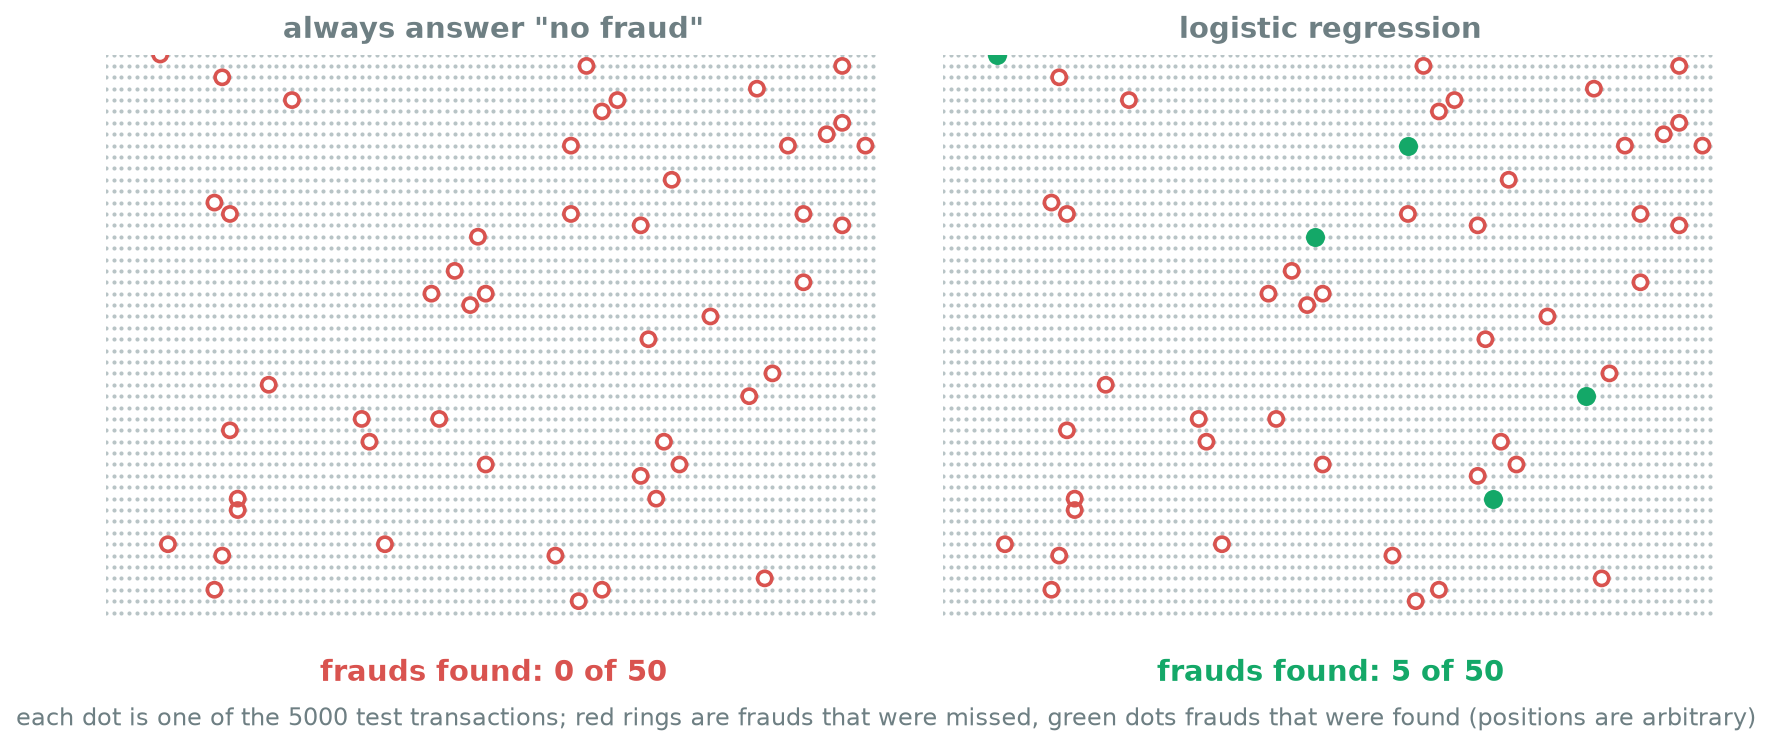

*Figure 4.1 — The 5000 test transactions, 50 of them fraud. The rule that always answers "no fraud" finds none of the frauds and still scores 0.990; the logistic regression finds 5 of 50 and scores 0.991. Almost every dot is a legitimate transaction, which is why accuracy hides the failure.*

## 1. A model with 99% accuracy

Here is a made-up fraud-detection problem: 20,000 transactions, of which 1% are fraud. We hold back 5,000 for testing, and 50 of them are fraud.

> **Pause:** a model scores 99.1% on this test set. Would you put it into use?
>
> - **A.** Yes: 99.1% is excellent.
> - **B.** Not yet: first compare it with a rule that always says no.
> - **C.** No: accuracy is never a useful measure.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** A rule that always answers "no fraud" scores 0.990 and finds none of the 50 frauds. The logistic regression scores 0.991 and finds only 5 of them, so it is no use either.

</details>

Two candidates, side by side:

- a rule that always answers "no fraud" scores 0.990 and finds none of the 50 frauds;
- a logistic regression scores 0.991 and finds 5 of the 50 (10%).

Both look excellent by accuracy. The logistic regression is no use either: it misses 45 of 50 frauds. When one class is rare, accuracy is dominated by the common class, so a high score is easy. The rest of this session uses measures that look at each kind of mistake separately.

## 2. Three sets, three jobs

For the rest of the session we use the breast-cancer dataset that comes with scikit-learn: 569 tumours, each described by 30 measurements, labelled malignant or benign. We call malignant the **positive** case, because it is the one we want to find.

We split the rows three ways:

- the **training set** (341 rows) is for fitting and for tuning with cross-validation;
- the **validation set** (114 rows) is for decisions that need unseen data, such as choosing a threshold;
- the **test set** (114 rows) is opened once, at the end, to report the final score.

The sets differ in their jobs, not in size. If a decision is made by looking at the test set, even once, the test score is no longer an honest estimate. This is what Session 2's leakage looked like, in a quieter form.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)  # scikit-learn codes malignant as 0; flip it so 1 = malignant, the case we want to find

X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED)

print(f"Training {len(X_train)}, validation {len(X_val)}, test {len(X_test)}")
print(f"Malignant cases: {y_train.sum()} in training, {y_val.sum()} in validation, {y_test.sum()} in test")
print(f"Baseline accuracy (always 'benign'): {1 - y_val.mean():.3f}")

Training 341, validation 114, test 114
Malignant cases: 127 in training, 43 in validation, 42 in test
Baseline accuracy (always 'benign'): 0.623


The baseline is "always benign", which scores 0.623 on the validation set. 43 of the validation rows and 42 of the test rows are malignant.

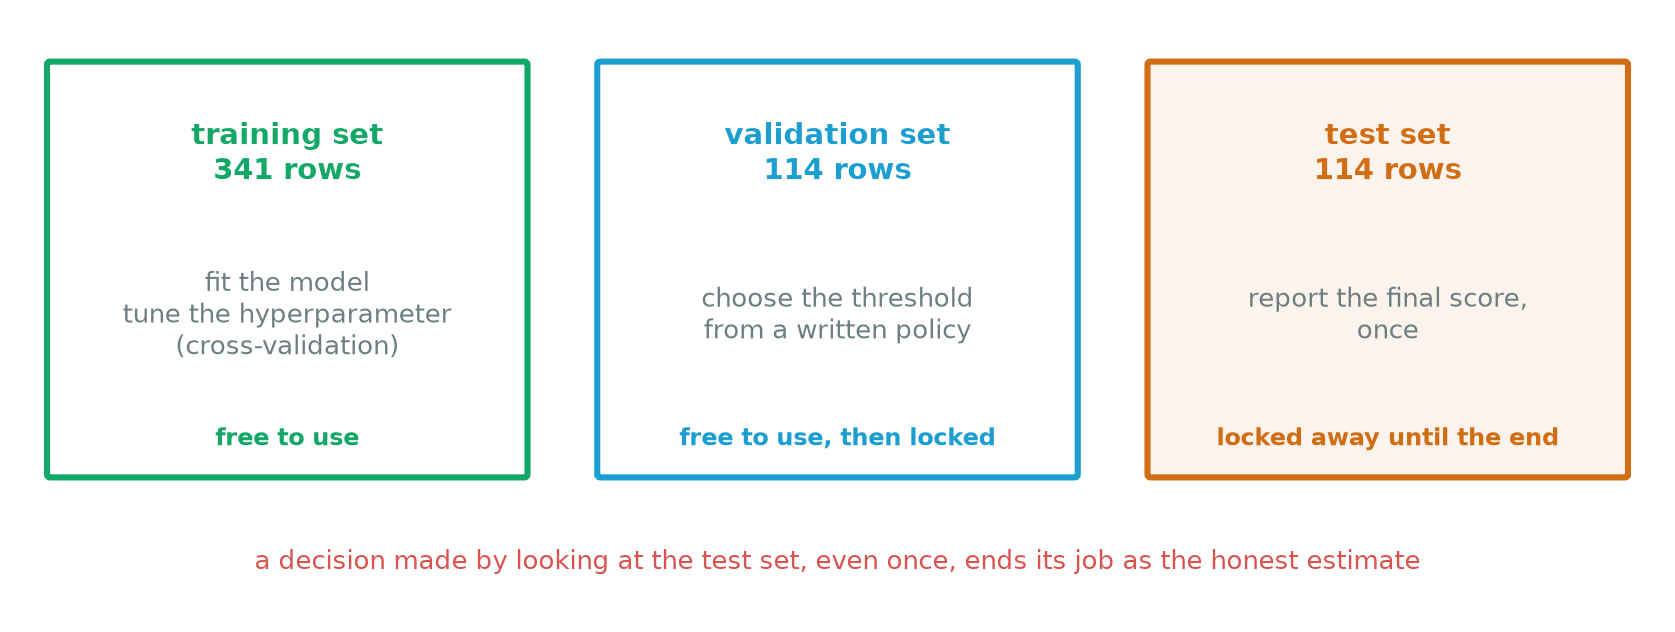

*Figure 4.2 — Three sets, three jobs. The training set (341 rows) is for fitting and tuning, the validation set (114 rows) is for decisions that need unseen data such as the threshold, and the test set (114 rows) is opened once at the end.*

## 3. Step 1: tune the model with cross-validation, on the training set only

Logistic regression has one setting that we choose ourselves, `C`, which controls how strongly the model is held back from fitting the training data too closely (smaller `C` means a stronger hold). Settings like this are called **hyperparameters**.

To compare values of `C` without touching the validation or test sets, we use **5-fold cross-validation** on the training set. The 341 rows are split into five parts. For each value of `C`, the model is trained five times, each time leaving out one part and scoring on it, and the five scores are averaged.

In [3]:
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED))
grid = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}
search = GridSearchCV(pipeline, grid, scoring="f1", cv=5).fit(X_train, y_train)

results = pd.DataFrame({"C": grid["logisticregression__C"], "mean F1": search.cv_results_["mean_test_score"], "std": search.cv_results_["std_test_score"]})
print(results.round(3).to_string(index=False))
print("\nBest:", search.best_params_)
model = search.best_estimator_

      C  mean F1   std
  0.001    0.777 0.057
  0.010    0.928 0.038
  0.100    0.955 0.015
  1.000    0.972 0.016
 10.000    0.951 0.021
100.000    0.942 0.035

Best: {'logisticregression__C': 1}


The mean F1 is highest at `C = 1` (0.972, with a spread of 0.016 between folds) and falls on both sides: 0.777 at `C = 0.001`, where the model is held back too much, and 0.942 at `C = 100`. F1 is a single number that combines precision and recall (both are explained next). `GridSearchCV` refits the best setting on the whole training set, and that is the model used from here on.

## 4. The confusion matrix and what to read from it

Each prediction falls into one of four boxes: a malignant case found (true positive), a malignant case missed (false negative), a benign case wrongly flagged (false positive), or a benign case correctly cleared (true negative).

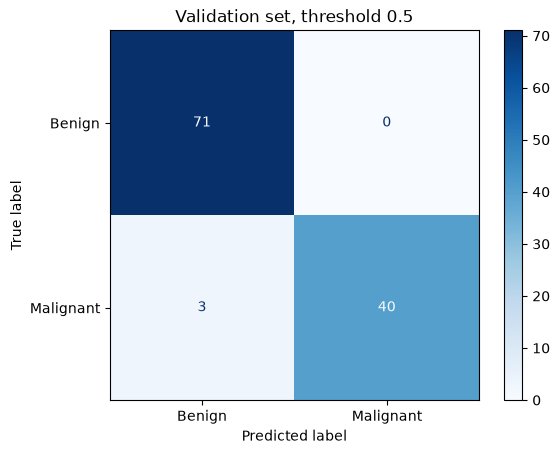

accuracy 0.974   precision 1.000   recall 0.930


In [4]:
val_probability = model.predict_proba(X_val)[:, 1]
val_predicted = (val_probability >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(y_val, val_predicted, display_labels=["Benign", "Malignant"], cmap="Blues")
plt.title("Validation set, threshold 0.5")
plt.show()
print(f"accuracy {accuracy_score(y_val, val_predicted):.3f}   precision {precision_score(y_val, val_predicted):.3f}   recall {recall_score(y_val, val_predicted):.3f}")

On the validation set at the default threshold of 0.5, there are 71 benign cases cleared, none wrongly flagged, 40 malignant cases found and 3 missed.

Three measures come out of these counts:

- **accuracy** is the share of all cases that are right: 0.974;
- **precision** is how often a "malignant" prediction is correct: 1.000 here, since nothing benign was flagged;
- **recall** is the share of malignant cases that were found: 0.930 (40 of 43).

The two kinds of error carry different costs. A missed malignant case (a false negative) means a patient goes untreated. A false alarm (a false positive) means extra tests. Recall tells us about the first and precision about the second, and accuracy mixes them together.

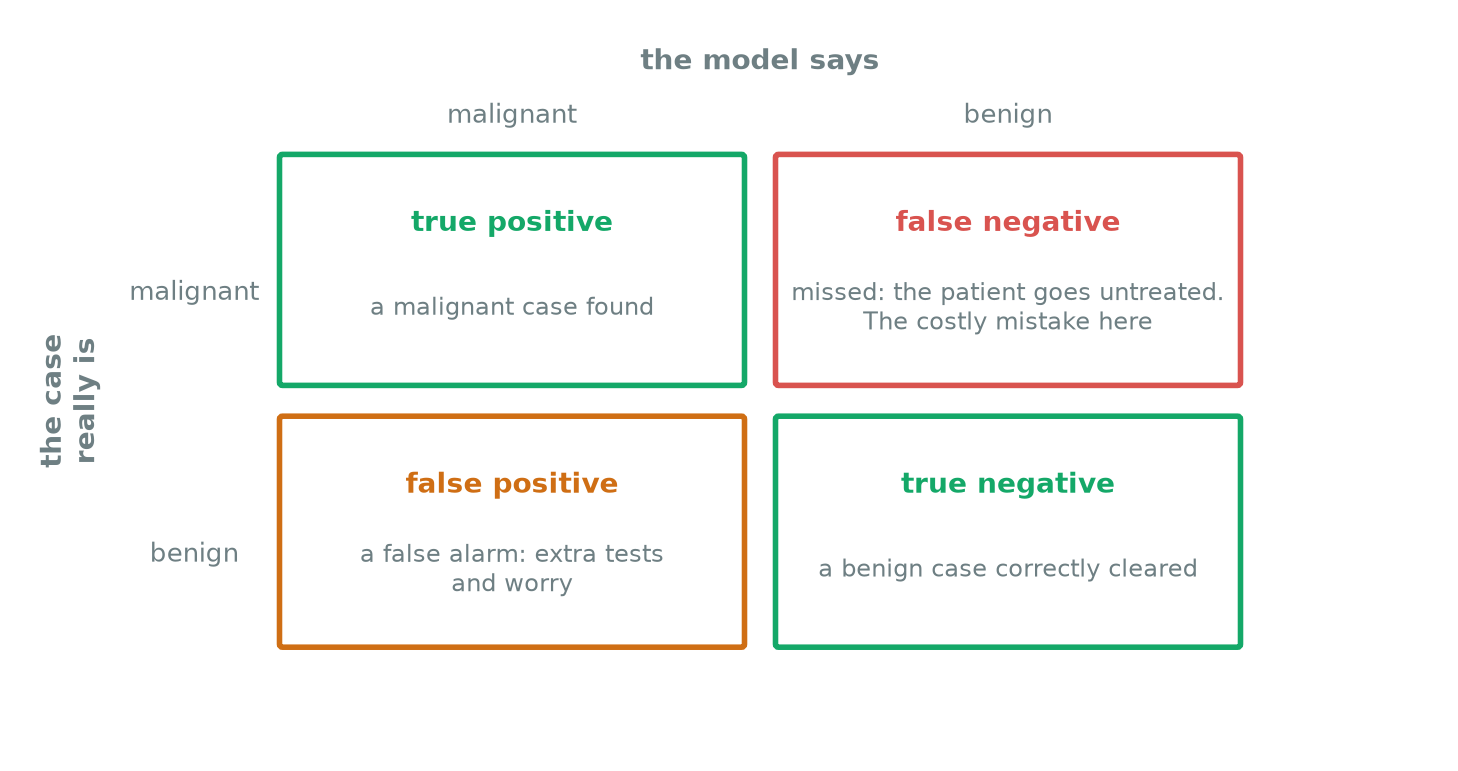

*Figure 4.3 — The four boxes of the confusion matrix, with what each kind of error costs in the cancer problem. A missed malignant case is the costly mistake; a false alarm costs extra tests.*

## 5. Step 2: choose the threshold with a stated policy

The model gives each tumour a score between 0 and 1. A **threshold** turns the score into a decision: flag as malignant if the score is at least the threshold. The default is 0.5, but nothing makes 0.5 the right choice. Lowering the threshold flags more cases, which raises recall and lowers precision.

> **Pause:** which mistake is worse here, a missed malignant case or a false alarm? Decide what you would ask of the model before looking at the plot.

We state a policy first: **find at least 95% of the malignant cases, and otherwise keep false alarms as low as possible.** In practice that means picking the highest threshold whose validation recall is at least 0.95.

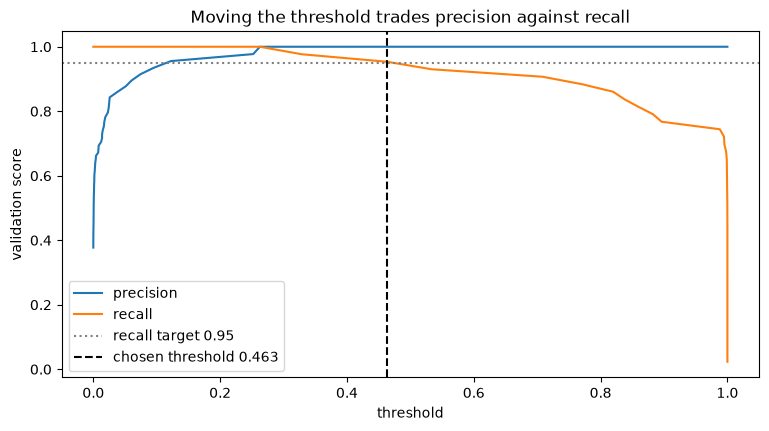

For comparison, maximising F1 on this validation set would reach F1 = 1.000.

Threshold 0.463 on the validation set:
precision 1.000   recall 0.953
malignant cases missed: 2 of 43   benign cases flagged: 0 of 71


In [5]:
precision, recall, thresholds = precision_recall_curve(y_val, val_probability)
precision, recall = precision[:-1], recall[:-1]  # one value per threshold

chosen = thresholds[recall >= 0.95].max()  # the highest threshold that still finds at least 95% of malignant cases
chosen_predicted = (val_probability >= chosen).astype(int)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, precision, label="precision")
ax.plot(thresholds, recall, label="recall")
ax.axhline(0.95, color="grey", linestyle=":", label="recall target 0.95")
ax.axvline(chosen, color="k", linestyle="--", label=f"chosen threshold {chosen:.3f}")
ax.set(xlabel="threshold", ylabel="validation score", title="Moving the threshold trades precision against recall")
ax.legend(loc="lower left")
plt.show()

f1 = 2 * precision * recall / (precision + recall)
print(f"For comparison, maximising F1 on this validation set would reach F1 = {f1.max():.3f}.\n")
print(f"Threshold {chosen:.3f} on the validation set:")
print(f"precision {precision_score(y_val, chosen_predicted):.3f}   recall {recall_score(y_val, chosen_predicted):.3f}")
print(f"malignant cases missed: {int(((chosen_predicted == 0) & (y_val == 1)).sum())} of {y_val.sum()}   benign cases flagged: {int(((chosen_predicted == 1) & (y_val == 0)).sum())} of {(y_val == 0).sum()}")

This comes out at 0.463. On the validation set that threshold misses 2 of 43 malignant cases (recall 0.953) and flags none of the 71 benign cases.

The printed comparison shows why a policy is better than a "best score" search. Maximising F1 on this validation set would reach F1 = 1.000, a perfect score on 43 malignant cases. That is a sign the threshold would be fitted to these particular 43 cases, which is overfitting of the kind from Session 3 but with a threshold in place of a tree. A stated target (95% of malignant cases found) says what we want and doesn't depend on a lucky validation set.

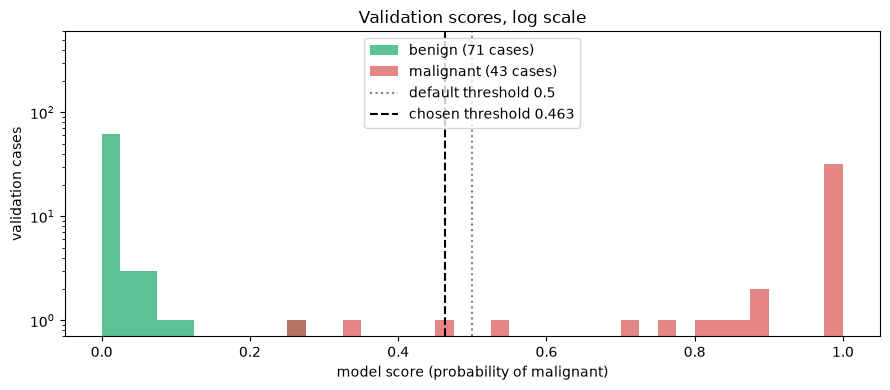

malignant cases below 0.463: 2, with scores [0.263, 0.329]


In [6]:
# Figure 4.4: the validation scores of the two kinds of case, and the two thresholds
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(val_probability[y_val == 0], bins=bins, alpha=0.7, color="#14A868", label=f"benign ({(y_val == 0).sum()} cases)")
ax.hist(val_probability[y_val == 1], bins=bins, alpha=0.7, color="#D9534F", label=f"malignant ({(y_val == 1).sum()} cases)")
ax.axvline(0.5, color="gray", ls=":", label="default threshold 0.5")
ax.axvline(chosen, color="k", ls="--", label=f"chosen threshold {chosen:.3f}")
ax.set(xlabel="model score (probability of malignant)", ylabel="validation cases", yscale="log", title="Validation scores, log scale")
ax.set_ylim(0.7, 600); ax.legend(loc="upper center")
plt.tight_layout(); plt.show()
missed = val_probability[(y_val == 1) & (val_probability < chosen)]
print(f"malignant cases below {chosen:.3f}: {len(missed)}, with scores {np.round(np.sort(missed), 3).tolist()}")

*Figure 4.4 — The model's validation scores for the 71 benign and the 43 malignant cases, with the default threshold 0.5 and the chosen 0.463. Almost every case sits at one end or the other; the two malignant cases that fall below 0.463 are the ones the chosen threshold still misses.*

## 6. Step 3: lock everything, then open the test set once

The model, its hyperparameter and the threshold are now fixed. We score the test set one time.

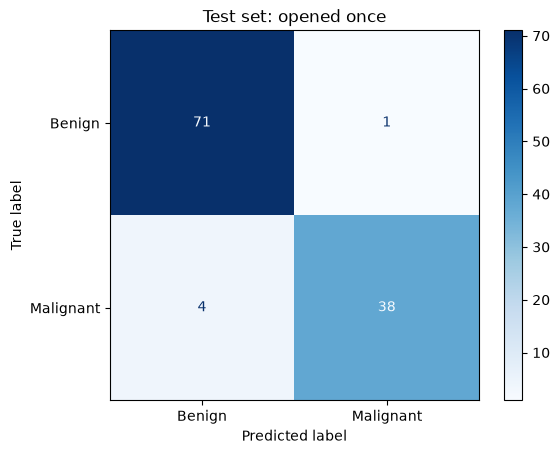

              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [7]:
test_probability = model.predict_proba(X_test)[:, 1]
test_predicted = (test_probability >= chosen).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, test_predicted, display_labels=["Benign", "Malignant"], cmap="Blues")
plt.title("Test set: opened once")
plt.show()
print(classification_report(y_test, test_predicted, target_names=["Benign", "Malignant"]))

On the 114 test cases the model finds 38 of the 42 malignant tumours (recall 0.905), misses 4, and wrongly flags 1 of the 72 benign ones (precision 0.974). Overall accuracy is 0.956.

The policy asked for 95% recall, and the validation set agreed (0.953), but the test set gives 0.905. With only 42 malignant cases, each one is worth 2.4 points of recall, so missing four rather than two moves the number a long way. The honest reading is that the threshold met its target on the data it was chosen on and falls a little short on new data.

We don't go back and lower the threshold to improve the test recall. That would turn the test set into a second validation set, and we would have no unseen data left to report. A larger validation set, or choosing the threshold from cross-validated predictions on all the development data, would give a steadier threshold, and a stricter target (such as 0.98) would leave room for this kind of drop. Both are changes to make before the final test, not after.

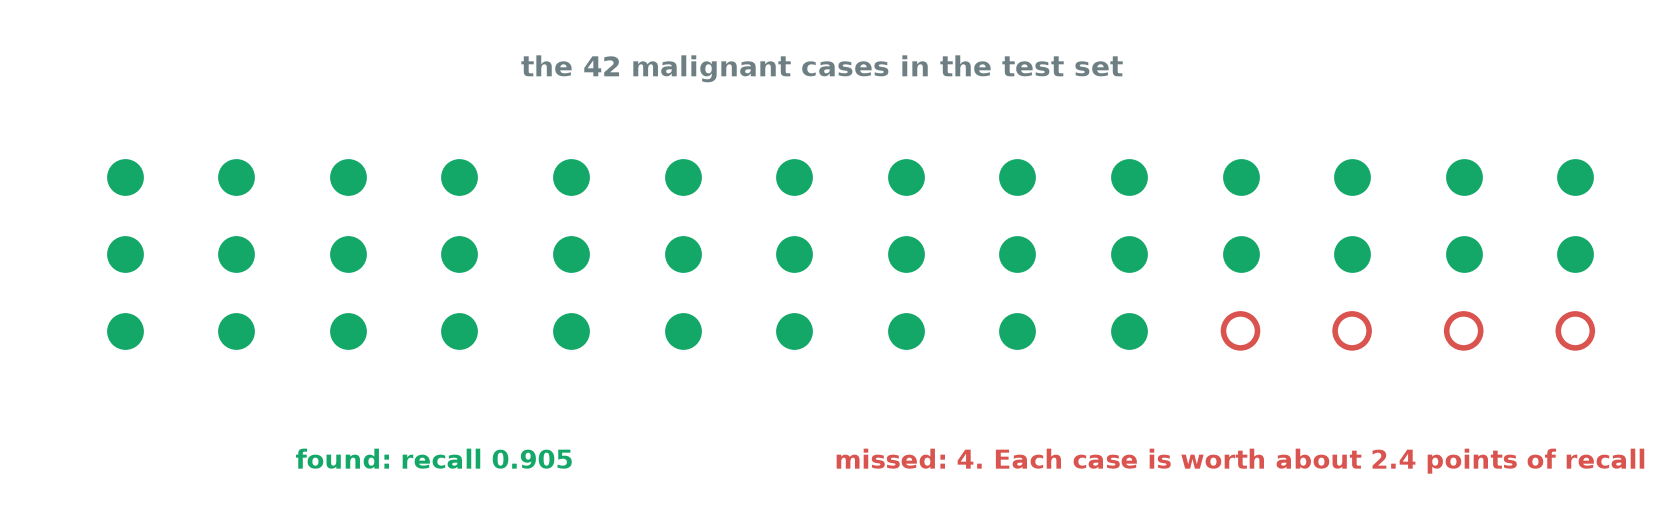

*Figure 4.5 — The 42 malignant test cases as dots. With so few, one case is worth about 2.4 points of recall, so missing four rather than two moves the number a long way.*

## The protocol, in order

1. **Check the baseline.** On imbalanced data, accuracy needs the baseline next to it.
2. **Split** into training, validation and test sets. Put the test set away.
3. **Tune** hyperparameters with cross-validation on the training set.
4. **Choose the threshold** on the validation set, from a policy you wrote down before looking.
5. **Lock** the model, hyperparameters and threshold.
6. **Test once**, and report the result as it is, including where it falls short.

> **Callback · Advanced Sessions 10 and 11.** The advanced course puts an interval on every benchmark score, checks a language-model judge in both answer orders (Session 10), and shows how a lucky run inflates a winning choice (Session 11). All of it builds on the validation and test discipline of this session.

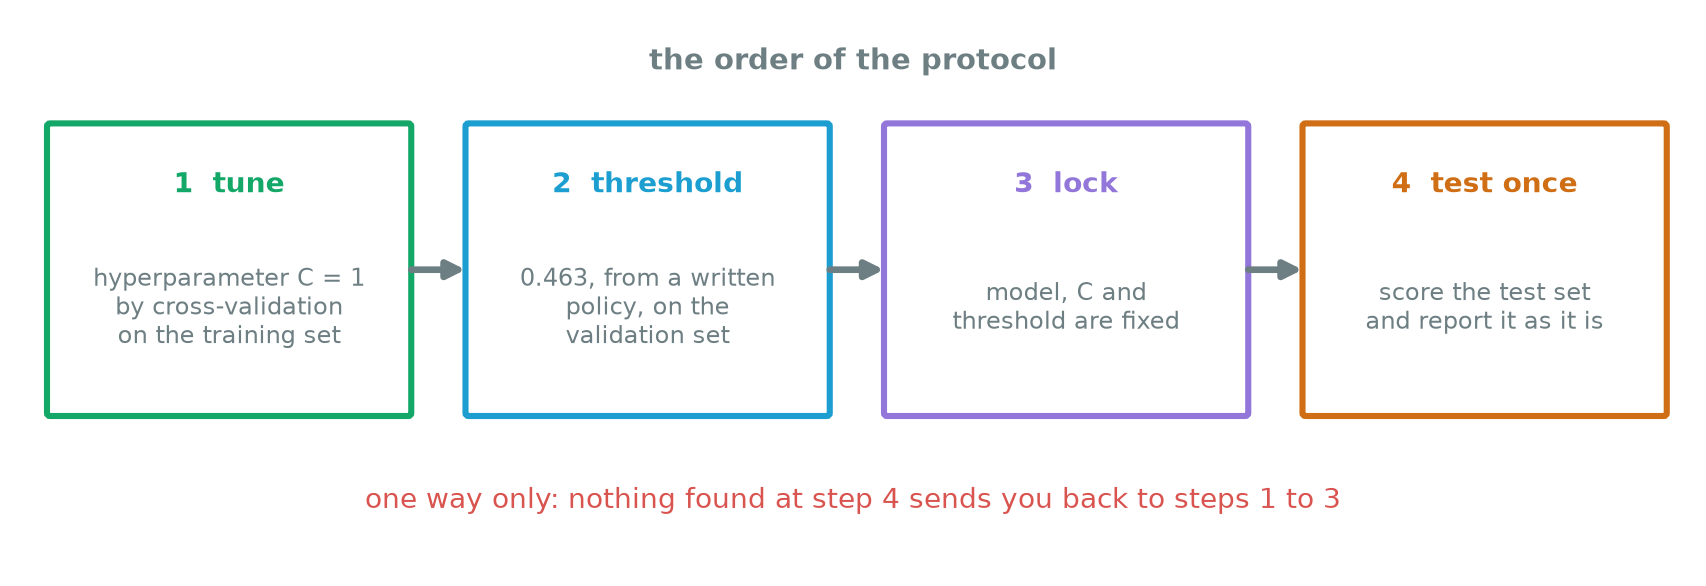

*Figure 4.6 — The protocol as a one-way track: tune the hyperparameter (C = 1), choose the threshold (0.463), lock everything, then score the test set once. There is no arrow back; going back would turn the test set into a second validation set.*

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## The metrics

With true positives $TP$, false positives $FP$, false negatives $FN$ and true negatives $TN$:

$$
\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\text{precision}=\frac{TP}{TP+FP},\quad
\text{recall}=\frac{TP}{TP+FN},
$$

$$
F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}} .
$$

$F_1$ is the harmonic mean of precision and recall, so it is low when either one is low. It counts a false alarm and a missed case as equally bad, which is rarely true in practice.

## Learning curves

A learning curve trains the model on growing fractions of the training data and plots the score. It tells you whether more data is likely to help. Here (training data only, 5-fold cross-validation) the training accuracy sits at 0.99 throughout while the cross-validated accuracy climbs from 0.930 with 27 examples to 0.979 with 272. The two lines are still closing, so more data would help a little, and the gap of about one point at the end is small.

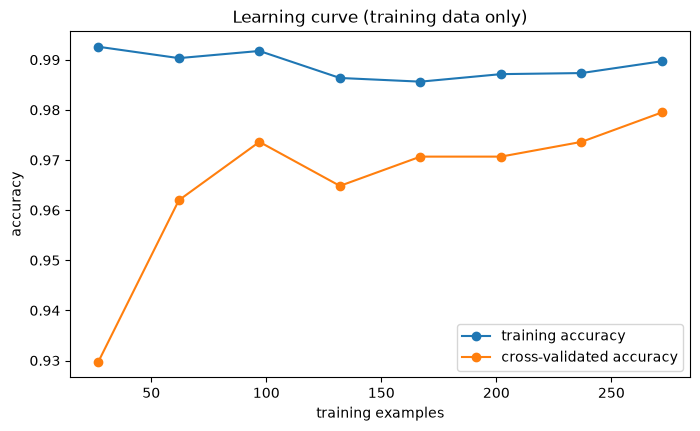

 examples  train  cross-validated
       27  0.993            0.930
       62  0.990            0.962
       97  0.992            0.974
      132  0.986            0.965
      167  0.986            0.971
      202  0.987            0.971
      237  0.987            0.974
      272  0.990            0.979


In [8]:
sizes, train_scores, cv_scores = learning_curve(model, X_train, y_train, cv=5, train_sizes=np.linspace(0.1, 1.0, 8), shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, train_scores.mean(axis=1), marker="o", label="training accuracy")
ax.plot(sizes, cv_scores.mean(axis=1), marker="o", label="cross-validated accuracy")
ax.set(xlabel="training examples", ylabel="accuracy", title="Learning curve (training data only)")
ax.legend()
plt.show()
print(pd.DataFrame({"examples": sizes, "train": train_scores.mean(axis=1).round(3), "cross-validated": cv_scores.mean(axis=1).round(3)}).to_string(index=False))

## Distribution shift

A test score estimates performance on data like the test set. If the model is used at another hospital, with different equipment or a different mix of patients, the score can change. That problem is called **distribution shift**, and no amount of careful splitting at training time guards against it.

## Regression metrics

When the target is a number, the common measures are the mean absolute error and the root mean squared error:

$$
\text{MAE}=\frac1n\sum_i|y_i-\hat y_i|,\qquad
\text{RMSE}=\sqrt{\frac1n\sum_i(y_i-\hat y_i)^2}.
$$

MAE is the average miss in the target's own units. RMSE punishes large misses more heavily. The coefficient of determination compares the model with always predicting the mean:

$$
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.
$$

It is 1 for a perfect model, 0 for one no better than the mean, and negative for one that is worse.